# Klasifikasi Daun Cabai

## Perbandingan tiga CNN pralatih

Persiapan dataset satu kali dilakukan melalui scripts/prepare_data.py. Notebook memakai hasil ekstraksi, audit, dan manifest yang telah diverifikasi; Run All tidak mengulang persiapan dataset.


### 1. Metodologi

Mengikuti keputusan pemilik proyek, rancangan PPT Progress I menjadi acuan: transfer learning ImageNet dua tahap, masukan RGB 224 x 224, normalisasi dari bobot pralatih, dan Macro-F1 validasi sebagai metrik utama. Manifest group-aware 70:15:15 dan seed 42/43/44 dipertahankan. Data test hanya disiapkan untuk evaluasi akhir.


### 2. Perangkat

In [1]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Perangkat:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE))


PyTorch: 2.10.0+cu128
CUDA: 12.8
Perangkat: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


### 3. Pustaka

In [2]:
import csv
import json
import os
import random
import time
from datetime import datetime
from collections import Counter, defaultdict
from pathlib import Path, PurePosixPath

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import (
    EfficientNet_B0_Weights,
    MobileNet_V3_Small_Weights,
    ResNet50_Weights,
    efficientnet_b0,
    mobilenet_v3_small,
    resnet50,
)
from torchvision.transforms import v2

print("TorchVision:", torchvision.__version__)
print("Macro-F1 dihitung dari matriks kebingungan PyTorch")

from IPython.display import Image as NotebookImage, Markdown, display


TorchVision: 0.25.0+cu128
Macro-F1 dihitung dari matriks kebingungan PyTorch


### 4. Konfigurasi dan manifest

Notebook hanya membaca artefak persiapan. Jika folder atau manifest belum tersedia, jalankan proses persiapan dataset satu kali secara terpisah.


In [3]:
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = Path(os.environ.get("DL_CABAI_DATA_DIR", PROJECT_ROOT / "data")).expanduser().resolve()
IMAGE_DIR = DATA_DIR / "extracted"
PROCESSED_DIR = DATA_DIR / "processed"
RUNS_DIR = PROCESSED_DIR / "runs"
torch.hub.set_dir(str(PROCESSED_DIR / "torch_hub"))
MANIFEST_PATH = PROCESSED_DIR / "split_manifest.csv"
CLASS_LABELS = (
    "Bacterial Spot",
    "Cercospora Leaf Spot",
    "Curl Virus",
    "Healthy Leaf",
    "Nutrient Deficiency",
    "Powdery Mildew",
)
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_LABELS)}
SPLITS = ("train", "validation", "test")
DEFAULT_SEEDS = (42, 43, 44)
PILOT_SEED = 42
RESULT_DIR = RUNS_DIR / f"mobilenet_v3_small_seed_{PILOT_SEED}"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

BASELINE_CONFIG = {
    "head_epochs": 3,
    "head_learning_rate": 1e-3,
    "fine_tune_epochs": 8,
    "fine_tune_learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.1,
    "cosine_eta_min": 1e-6,
}
AUGMENTATION = {
    "horizontal_flip": 0.5,
    "rotation_degrees": 15,
    "brightness": 0.2,
    "contrast": 0.2,
}

assert IMAGE_DIR.is_dir(), f"Folder citra hasil persiapan tidak ditemukan: {IMAGE_DIR}"
assert MANIFEST_PATH.is_file(), f"Manifest tidak ditemukan: {MANIFEST_PATH}"
with (PROCESSED_DIR / "audit.json").open(encoding="utf-8") as stream:
    audit_summary = json.load(stream)
with MANIFEST_PATH.open(newline="", encoding="utf-8-sig") as stream:
    manifest_rows = list(csv.DictReader(stream))
for row in manifest_rows:
    row["seed"] = int(row["seed"])

assert tuple(audit_summary["configured_seeds"]) == DEFAULT_SEEDS
assert all(seed in {row["seed"] for row in manifest_rows} for seed in DEFAULT_SEEDS)
print("Citra hasil persiapan:", IMAGE_DIR)
print("Baris manifest:", len(manifest_rows))
print("Jumlah citra valid:", audit_summary["raw_image_files"])
print("Citra unik per kelas:", audit_summary["exact_unique_count_by_class"])

print("Cache bobot TorchVision:", torch.hub.get_dir())


Citra hasil persiapan: E:\OMING\Coding\Python\Deep-Learning-Cabai\data\extracted
Baris manifest: 26451
Jumlah citra valid: 8817
Citra unik per kelas: {'Bacterial Spot': 1280, 'Cercospora Leaf Spot': 1683, 'Curl Virus': 1582, 'Healthy Leaf': 1481, 'Nutrient Deficiency': 1067, 'Powdery Mildew': 843}
Cache bobot TorchVision: E:\OMING\Coding\Python\Deep-Learning-Cabai\data\processed\torch_hub


### 5. Transformasi dan augmentasi

Semua citra menjadi RGB 224 x 224 dan dinormalisasi memakai mean/std bobot MobileNetV3-Small ImageNet1K V1. Augmentasi acak hanya ada pada transformasi train.


In [4]:
MODEL_WEIGHTS = {
    "MobileNetV3-Small": MobileNet_V3_Small_Weights.IMAGENET1K_V1,
    "ResNet-50": ResNet50_Weights.IMAGENET1K_V2,
    "EfficientNet-B0": EfficientNet_B0_Weights.IMAGENET1K_V1,
}
MODEL_SLUGS = {
    "ResNet-50": "resnet50",
    "EfficientNet-B0": "efficientnet_b0",
}
WEIGHTS = MODEL_WEIGHTS["MobileNetV3-Small"]
WEIGHT_TRANSFORM = WEIGHTS.transforms()
IMAGE_MEAN = tuple(WEIGHT_TRANSFORM.mean)
IMAGE_STD = tuple(WEIGHT_TRANSFORM.std)


def make_transform(training=False):
    steps = [v2.ToImage(), v2.Resize(IMAGE_SIZE, antialias=True)]
    if training:
        steps.extend([
            v2.RandomHorizontalFlip(p=AUGMENTATION["horizontal_flip"]),
            v2.RandomRotation(AUGMENTATION["rotation_degrees"]),
            v2.ColorJitter(
                brightness=AUGMENTATION["brightness"],
                contrast=AUGMENTATION["contrast"],
            ),
        ])
    steps.extend([
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
    ])
    return v2.Compose(steps)


print("Normalisasi:", IMAGE_MEAN, IMAGE_STD)


Normalisasi: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


### 6. Dataset dan DataLoader

Class weight memakai baris train saja. Loader validasi dan test tidak memakai augmentasi.


In [5]:
class ManifestDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        relative_path = PurePosixPath(row["relative_path"])
        if relative_path.is_absolute() or ".." in relative_path.parts:
            raise ValueError(f"Path manifest tidak aman: {relative_path}")
        path = IMAGE_DIR.joinpath(*relative_path.parts).resolve()
        if IMAGE_DIR not in path.parents or not path.is_file():
            raise FileNotFoundError(path)
        with Image.open(path) as image:
            image = image.convert("RGB")
            return self.transform(image), CLASS_TO_INDEX[row["class_name"]]


def class_weights_from_manifest(rows, seed):
    train_labels = torch.tensor([
        CLASS_TO_INDEX[row["class_name"]]
        for row in rows
        if row["seed"] == seed and row["split"] == "train" and row["status"] == "included"
    ])
    counts = torch.bincount(train_labels, minlength=len(CLASS_LABELS)).float()
    if torch.any(counts == 0):
        raise ValueError("Setiap kelas harus muncul pada data train")
    return counts.sum() / (len(CLASS_LABELS) * counts)


def build_loaders(seed=PILOT_SEED, batch_size=BATCH_SIZE):
    selected = [
        row for row in manifest_rows
        if row["seed"] == seed and row["status"] == "included"
    ]
    loaders = {}
    for split in SPLITS:
        rows = [row for row in selected if row["split"] == split]
        generator = torch.Generator().manual_seed(seed) if split == "train" else None
        loaders[split] = DataLoader(
            ManifestDataset(rows, make_transform(training=(split == "train"))),
            batch_size=batch_size,
            shuffle=(split == "train"),
            num_workers=0,
            pin_memory=(DEVICE.type == "cuda"),
            generator=generator,
        )
    return loaders, class_weights_from_manifest(manifest_rows, seed)


random.seed(PILOT_SEED)
np.random.seed(PILOT_SEED)
torch.manual_seed(PILOT_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(PILOT_SEED)

loaders, class_weights = build_loaders()
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE),
    label_smoothing=BASELINE_CONFIG["label_smoothing"],
)
for split in SPLITS:
    print(f"{split}: {len(loaders[split].dataset)} citra")
print("Class weight train-only:", class_weights.tolist())


train: 5556 citra
validation: 1191 citra
test: 1189 citra
Class weight train-only: [1.0334821939468384, 0.7860780954360962, 0.8357400894165039, 0.8929604887962341, 1.2396252155303955, 1.5694915056228638]


### 7. Distribusi kelas dan batch contoh

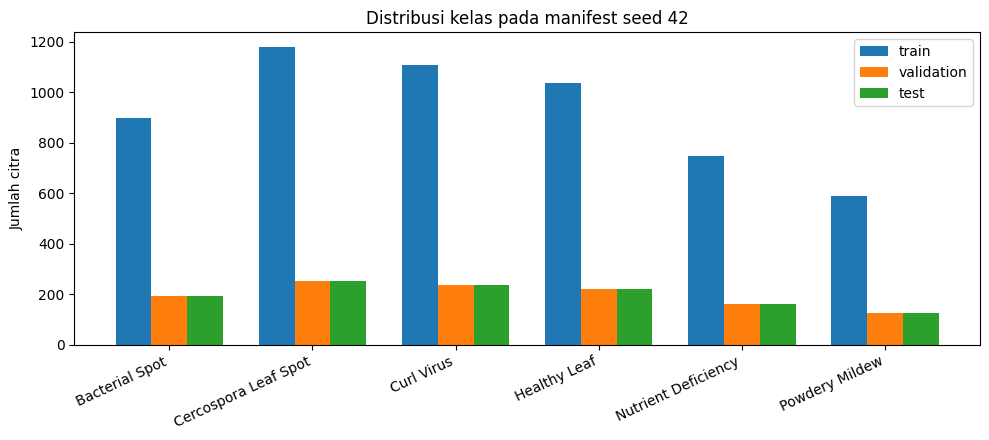

Batch: (32, 3, 224, 224) [4, 2, 3, 5, 3, 0, 4, 4]


In [6]:
selected_rows = [
    row for row in manifest_rows
    if row["seed"] == PILOT_SEED and row["status"] == "included"
]
counts = {
    split: Counter(row["class_name"] for row in selected_rows if row["split"] == split)
    for split in SPLITS
}
positions = np.arange(len(CLASS_LABELS))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, split in enumerate(SPLITS):
    values = [counts[split][label] for label in CLASS_LABELS]
    ax.bar(positions + (offset - 1) * bar_width, values, bar_width, label=split)
ax.set_xticks(positions, CLASS_LABELS, rotation=25, ha="right")
ax.set_ylabel("Jumlah citra")
ax.set_title("Distribusi kelas pada manifest seed 42")
ax.legend()
fig.tight_layout()
plt.show()

images, labels = next(iter(loaders["train"]))
print("Batch:", tuple(images.shape), labels[:8].tolist())
assert images.shape[1:] == (3, 224, 224)


### 8. Arsitektur CNN pralatih

MobileNetV3-Small, ResNet-50, dan EfficientNet-B0 memakai bobot ImageNet yang ditetapkan melalui TorchVision.


In [7]:
def build_model(architecture="MobileNetV3-Small", pretrained=True, device=DEVICE):
    weights = MODEL_WEIGHTS[architecture] if pretrained else None
    if architecture == "MobileNetV3-Small":
        model = mobilenet_v3_small(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_LABELS))
    elif architecture == "ResNet-50":
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(CLASS_LABELS))
    elif architecture == "EfficientNet-B0":
        model = efficientnet_b0(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_LABELS))
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {architecture}")
    return model.to(device)


print("Arsitektur:", ", ".join(MODEL_WEIGHTS))


Arsitektur: MobileNetV3-Small, ResNet-50, EfficientNet-B0


### 9. Training dan validasi

Tahap pertama melatih classifier dengan feature extractor dan BatchNorm backbone dibekukan. Tahap kedua melakukan fine-tuning seluruh jaringan. Checkpoint terbaik tiap tahap dipilih dari Macro-F1 validasi; test tidak dipakai.


In [8]:
def run_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None,
    freeze_features=False,
):
    training = optimizer is not None
    model.train(training)
    if training and freeze_features:
        classifier = model.fc if hasattr(model, "fc") else model.classifier
        model.eval()
        classifier.train()

    total_loss = 0.0
    total_samples = 0
    true_labels, predicted_labels = [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)
            true_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(logits.argmax(dim=1).detach().cpu().tolist())

    if total_samples == 0:
        raise ValueError("DataLoader kosong")
    class_count = len(CLASS_LABELS)
    targets = torch.tensor(true_labels, dtype=torch.long)
    predictions = torch.tensor(predicted_labels, dtype=torch.long)
    confusion = torch.bincount(
        targets * class_count + predictions,
        minlength=class_count * class_count,
    ).reshape(class_count, class_count)
    true_positive = confusion.diag().float()
    false_positive = confusion.sum(dim=0) - true_positive
    false_negative = confusion.sum(dim=1) - true_positive
    denominator = 2 * true_positive + false_positive + false_negative
    macro_f1 = (2 * true_positive / denominator.clamp(min=1)).mean().item()
    return total_loss / total_samples, macro_f1


def train_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    device,
    seed,
    checkpoint_dir,
    config,
    architecture="MobileNetV3-Small",
    weights_name="IMAGENET1K_V1",
):
    stages = (
        ("classifier_head", True, config["head_epochs"], config["head_learning_rate"]),
        ("fine_tune_all", False, config["fine_tune_epochs"], config["fine_tune_learning_rate"]),
    )
    history = []
    classifier = model.fc if hasattr(model, "fc") else model.classifier
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    for stage_name, freeze_features, configured_epochs, learning_rate in stages:
        epochs = configured_epochs
        for parameter in model.parameters():
            parameter.requires_grad = not freeze_features
        if freeze_features:
            for parameter in classifier.parameters():
                parameter.requires_grad = True
            trainable_parameters = classifier.parameters()
        else:
            trainable_parameters = model.parameters()

        optimizer = torch.optim.AdamW(
            trainable_parameters,
            lr=learning_rate,
            weight_decay=config["weight_decay"],
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=config["cosine_eta_min"],
        )
        checkpoint_path = checkpoint_dir / f"{stage_name}_best.pth"
        best_validation_f1 = -1.0

        for epoch in range(1, epochs + 1):
            train_loss, train_f1 = run_epoch(
                model, train_loader, criterion, device, optimizer,
                freeze_features=freeze_features,
            )
            validation_loss, validation_f1 = run_epoch(
                model, validation_loader, criterion, device,
            )
            scheduler.step()
            history.append({
                "stage": stage_name,
                "epoch": epoch,
                "global_epoch": len(history) + 1,
                "train_loss": train_loss,
                "train_macro_f1": train_f1,
                "validation_loss": validation_loss,
                "validation_macro_f1": validation_f1,
            })
            print(
                f"{stage_name} {epoch}/{epochs}: "
                f"train loss {train_loss:.4f}, macro-F1 {train_f1:.4f}; "
                f"val loss {validation_loss:.4f}, macro-F1 {validation_f1:.4f}"
            )

            if validation_f1 > best_validation_f1:
                best_validation_f1 = validation_f1
                torch.save({
                    "model_state_dict": model.state_dict(),
                    "architecture": architecture,
                    "weights": weights_name,
                    "class_labels": list(CLASS_LABELS),
                    "seed": seed,
                    "stage": stage_name,
                    "epoch": epoch,
                    "validation_macro_f1": validation_f1,
                }, checkpoint_path)

        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state_dict"])

    return history


### 10. Visualisasi riwayat

In [9]:
def plot_history(history, save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for stage in dict.fromkeys(row["stage"] for row in history):
        rows = [row for row in history if row["stage"] == stage]
        epochs = [row["global_epoch"] for row in rows]
        axes[0].plot(epochs, [row["train_loss"] for row in rows], marker="o", label=f"{stage} train")
        axes[0].plot(epochs, [row["validation_loss"] for row in rows], marker="s", label=f"{stage} validation")
        axes[1].plot(epochs, [row["train_macro_f1"] for row in rows], marker="o", label=f"{stage} train")
        axes[1].plot(epochs, [row["validation_macro_f1"] for row in rows], marker="s", label=f"{stage} validation")
    axes[0].set_title("Loss")
    axes[1].set_title("Macro-F1")
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.legend()
        axis.grid(alpha=0.25)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=160)
    plt.close(fig)


### 11. Jalankan baseline (opsional)

Cell ini hanya melatih jika `JALANKAN_BASELINE` diubah menjadi `True`. Setiap training baru memakai folder eksperimen bertimestamp agar hasil lama tetap utuh. Untuk melihat hasil yang sudah ada, biarkan `False` dan jalankan semua cell.


In [10]:
JALANKAN_BASELINE = False

if JALANKAN_BASELINE:
    run_name = (
        f"mobilenet_v3_small_seed_{PILOT_SEED}_"
        f"{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
    )
    RESULT_DIR = RUNS_DIR / run_name
    RESULT_DIR.mkdir(parents=True, exist_ok=False)
    model = build_model("MobileNetV3-Small")

    experiment_config = {
        "architecture": "MobileNetV3-Small",
        "pretrained_weights": WEIGHTS.name,
        "seed": PILOT_SEED,
        "split_manifest": str(MANIFEST_PATH),
        "subset_sizes": {split: len(loader.dataset) for split, loader in loaders.items()},
        "input_shape": [3, *IMAGE_SIZE],
        "normalization": {"mean": list(IMAGE_MEAN), "std": list(IMAGE_STD)},
        "batch_size": BATCH_SIZE,
        "baseline_config": BASELINE_CONFIG,
        "augmentation": AUGMENTATION,
        "class_weights": class_weights.tolist(),
        "selection_metric": "validation_macro_f1",
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
        "pytorch": str(torch.__version__),
        "torchvision": torchvision.__version__,
        "started_at": datetime.now().astimezone().isoformat(timespec="seconds"),
        "status": "running",
    }
    config_path = RESULT_DIR / "experiment_config.json"
    config_path.write_text(json.dumps(experiment_config, indent=2) + chr(10), encoding="utf-8")

    training_started = time.perf_counter()
    history = train_model(
        model=model,
        train_loader=loaders["train"],
        validation_loader=loaders["validation"],
        criterion=criterion,
        device=DEVICE,
        seed=PILOT_SEED,
        checkpoint_dir=RESULT_DIR,
        config=BASELINE_CONFIG,
        architecture="MobileNetV3-Small",
        weights_name=WEIGHTS.name,
    )
    training_duration = time.perf_counter() - training_started
    (RESULT_DIR / "training_history.json").write_text(
        json.dumps(history, indent=2) + chr(10), encoding="utf-8"
    )

    stage_checkpoints = [
        torch.load(RESULT_DIR / f"{stage}_best.pth", map_location="cpu", weights_only=True)
        for stage in ("classifier_head", "fine_tune_all")
    ]
    best_checkpoint = max(stage_checkpoints, key=lambda item: item["validation_macro_f1"])
    best_path = RESULT_DIR / "best_checkpoint.pth"
    torch.save(best_checkpoint, best_path)
    experiment_config.update({
        "status": "completed",
        "training_duration_seconds": round(training_duration, 2),
        "best_stage": best_checkpoint["stage"],
        "best_epoch": best_checkpoint["epoch"],
        "best_validation_macro_f1": best_checkpoint["validation_macro_f1"],
        "best_checkpoint": best_path.name,
    })
    config_path.write_text(json.dumps(experiment_config, indent=2) + chr(10), encoding="utf-8")
    plot_history(history, save_path=RESULT_DIR / "training_curves.png")
    print("Artefak training tersimpan di:", RESULT_DIR)


### 12. Training ResNet-50 dan EfficientNet-B0 (opsional)

Cell ini melatih kedua arsitektur secara berurutan dengan seed 42, manifest, augmentasi, class weight, dan konfigurasi dua tahap yang sama. Setiap run memakai folder bertimestamp baru. Biarkan `JALANKAN_KOMPARASI = False` untuk Run All tanpa training ulang.

In [11]:
JALANKAN_KOMPARASI = False

if JALANKAN_KOMPARASI:
    for architecture in ("ResNet-50", "EfficientNet-B0"):
        random.seed(PILOT_SEED)
        np.random.seed(PILOT_SEED)
        torch.manual_seed(PILOT_SEED)
        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(PILOT_SEED)

        model = build_model(architecture)
        parameter_count = sum(parameter.numel() for parameter in model.parameters())
        model_loaders, model_class_weights = build_loaders(seed=PILOT_SEED, batch_size=BATCH_SIZE)
        model_criterion = nn.CrossEntropyLoss(
            weight=model_class_weights.to(DEVICE),
            label_smoothing=BASELINE_CONFIG["label_smoothing"],
        )

        run_name = (
            f"{MODEL_SLUGS[architecture]}_seed_{PILOT_SEED}_"
            f"{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
        )
        model_result_dir = RUNS_DIR / run_name
        model_result_dir.mkdir(parents=True, exist_ok=False)
        experiment_config = {
            "architecture": architecture,
            "pretrained_weights": MODEL_WEIGHTS[architecture].name,
            "seed": PILOT_SEED,
            "split_manifest": str(MANIFEST_PATH),
            "subset_sizes": {split: len(loader.dataset) for split, loader in model_loaders.items()},
            "input_shape": [3, *IMAGE_SIZE],
            "normalization": {"mean": list(IMAGE_MEAN), "std": list(IMAGE_STD)},
            "batch_size": BATCH_SIZE,
            "baseline_config": BASELINE_CONFIG,
            "augmentation": AUGMENTATION,
            "class_weights": model_class_weights.tolist(),
            "parameter_count": parameter_count,
            "selection_metric": "validation_macro_f1",
            "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
            "pytorch": str(torch.__version__),
            "torchvision": torchvision.__version__,
            "started_at": datetime.now().astimezone().isoformat(timespec="seconds"),
            "status": "running",
        }
        config_path = model_result_dir / "experiment_config.json"
        config_path.write_text(json.dumps(experiment_config, indent=2) + chr(10), encoding="utf-8")

        random.seed(PILOT_SEED)
        np.random.seed(PILOT_SEED)
        torch.manual_seed(PILOT_SEED)
        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(PILOT_SEED)
        training_started = time.perf_counter()
        history = train_model(
            model=model,
            train_loader=model_loaders["train"],
            validation_loader=model_loaders["validation"],
            criterion=model_criterion,
            device=DEVICE,
            seed=PILOT_SEED,
            checkpoint_dir=model_result_dir,
            config=BASELINE_CONFIG,
            architecture=architecture,
            weights_name=MODEL_WEIGHTS[architecture].name,
        )
        training_duration = time.perf_counter() - training_started
        (model_result_dir / "training_history.json").write_text(
            json.dumps(history, indent=2) + chr(10), encoding="utf-8"
        )

        stage_checkpoints = [
            torch.load(model_result_dir / f"{stage}_best.pth", map_location="cpu", weights_only=True)
            for stage in ("classifier_head", "fine_tune_all")
        ]
        best_checkpoint = max(stage_checkpoints, key=lambda item: item["validation_macro_f1"])
        best_history_row = max(history, key=lambda row: row["validation_macro_f1"])
        best_path = model_result_dir / "best_checkpoint.pth"
        torch.save(best_checkpoint, best_path)
        experiment_config.update({
            "status": "completed",
            "training_duration_seconds": round(training_duration, 2),
            "best_stage": best_checkpoint["stage"],
            "best_epoch": best_checkpoint["epoch"],
            "best_validation_macro_f1": best_checkpoint["validation_macro_f1"],
            "best_validation_loss": best_history_row["validation_loss"],
            "best_checkpoint": best_path.name,
        })
        config_path.write_text(json.dumps(experiment_config, indent=2) + chr(10), encoding="utf-8")
        plot_history(history, save_path=model_result_dir / "training_curves.png")
        print(
            f"Selesai: {architecture} | best validation Macro-F1 "
            f"{experiment_config['best_validation_macro_f1']:.4f} | "
            f"durasi {training_duration / 60:.1f} menit"
        )
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


### 13. Perbandingan dan hasil eksperimen

Tabel membandingkan checkpoint dengan validation Macro-F1 terbaik. Validation loss pada tabel berasal dari epoch checkpoint yang sama; data test tidak digunakan.

## Perbandingan tiga model

| Model | Validation Macro-F1 terbaik | Validation loss pada checkpoint | Parameter | Durasi (menit) |
|---|---:|---:|---:|---:|
| MobileNetV3-Small | 0.9725 | 0.5534 | 1,524,006 | 40.3 |
| ResNet-50 | 0.9804 | 0.5066 | 23,520,326 | 35.9 |
| EfficientNet-B0 | 0.9801 | 0.5426 | 4,015,234 | 32.7 |

### MobileNetV3-Small

Bobot ImageNet: `IMAGENET1K_V1`; checkpoint terbaik: `E:\OMING\Coding\Python\Deep-Learning-Cabai\data\processed\runs\mobilenet_v3_small_seed_42\best_checkpoint.pth`; durasi: 40.3 menit.

Jumlah parameter: 1,524,006.

Jumlah epoch: 11

| Epoch global | Tahap | Epoch tahap | Train loss | Train Macro-F1 | Validation loss | Validation Macro-F1 |
|---:|---|---:|---:|---:|---:|---:|
| 1 | classifier_head | 1 | 0.7673 | 0.8713 | 0.6419 | 0.9564 |
| 2 | classifier_head | 2 | 0.6001 | 0.9541 | 0.5898 | 0.9659 |
| 3 | classifier_head | 3 | 0.5568 | 0.9733 | 0.5796 | 0.9681 |
| 4 | fine_tune_all | 1 | 0.6917 | 0.9090 | 0.6874 | 0.9416 |
| 5 | fine_tune_all | 2 | 0.5519 | 0.9720 | 0.5900 | 0.9606 |
| 6 | fine_tune_all | 3 | 0.5311 | 0.9783 | 0.5534 | 0.9725 |
| 7 | fine_tune_all | 4 | 0.5197 | 0.9820 | 0.5515 | 0.9681 |
| 8 | fine_tune_all | 5 | 0.5081 | 0.9860 | 0.5464 | 0.9724 |
| 9 | fine_tune_all | 6 | 0.5023 | 0.9868 | 0.5450 | 0.9681 |
| 10 | fine_tune_all | 7 | 0.4973 | 0.9904 | 0.5450 | 0.9667 |
| 11 | fine_tune_all | 8 | 0.4951 | 0.9901 | 0.5449 | 0.9666 |

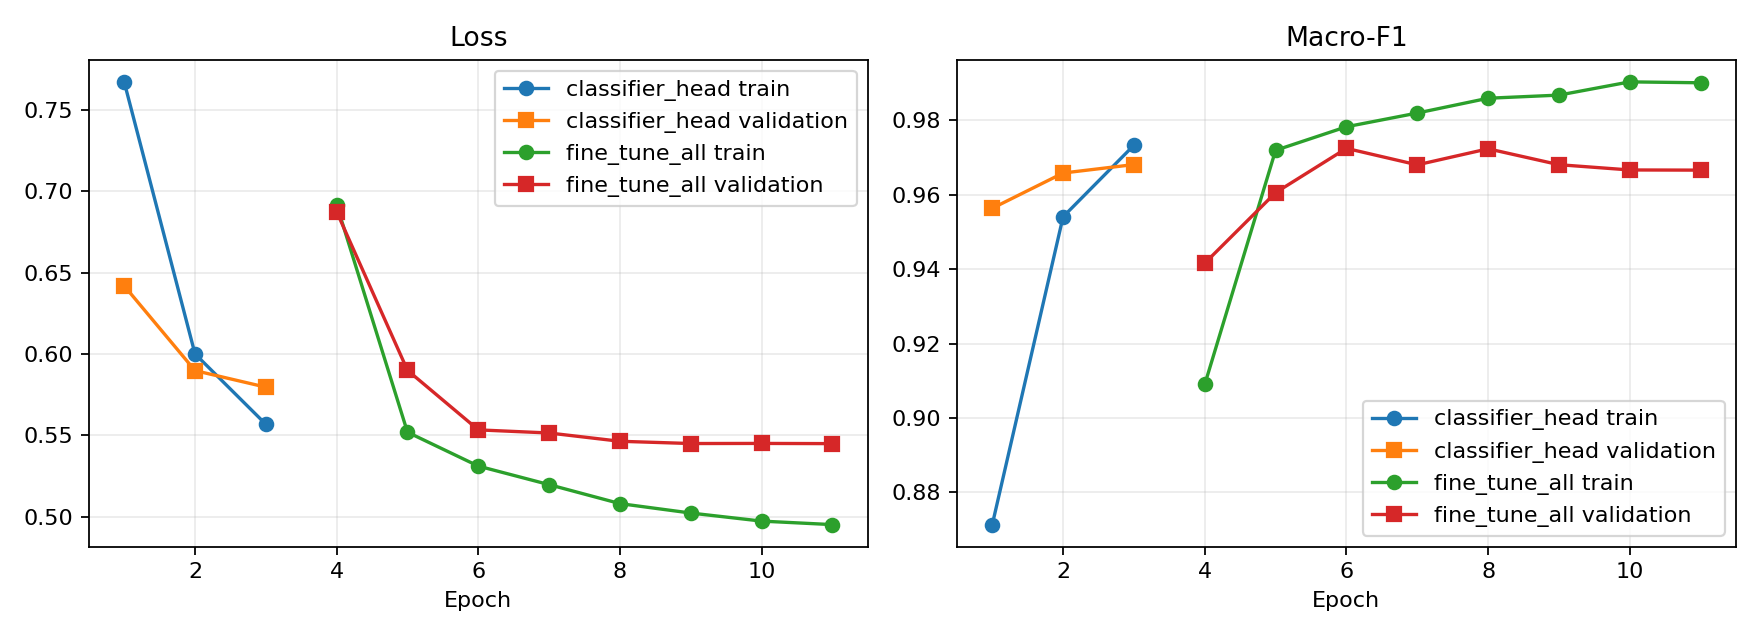

### ResNet-50

Bobot ImageNet: `IMAGENET1K_V2`; checkpoint terbaik: `E:\OMING\Coding\Python\Deep-Learning-Cabai\data\processed\runs\resnet50_seed_42_20261115_101121_042498\best_checkpoint.pth`; durasi: 35.9 menit.

Jumlah parameter: 23,520,326.

Jumlah epoch: 11

| Epoch global | Tahap | Epoch tahap | Train loss | Train Macro-F1 | Validation loss | Validation Macro-F1 |
|---:|---|---:|---:|---:|---:|---:|
| 1 | classifier_head | 1 | 1.0393 | 0.8226 | 0.8160 | 0.9123 |
| 2 | classifier_head | 2 | 0.7367 | 0.9095 | 0.7366 | 0.9310 |
| 3 | classifier_head | 3 | 0.6961 | 0.9244 | 0.7141 | 0.9404 |
| 4 | fine_tune_all | 1 | 0.6166 | 0.9375 | 0.5340 | 0.9781 |
| 5 | fine_tune_all | 2 | 0.5011 | 0.9816 | 0.5200 | 0.9722 |
| 6 | fine_tune_all | 3 | 0.4773 | 0.9909 | 0.5216 | 0.9782 |
| 7 | fine_tune_all | 4 | 0.4662 | 0.9939 | 0.5168 | 0.9767 |
| 8 | fine_tune_all | 5 | 0.4587 | 0.9961 | 0.5215 | 0.9756 |
| 9 | fine_tune_all | 6 | 0.4558 | 0.9966 | 0.5087 | 0.9780 |
| 10 | fine_tune_all | 7 | 0.4517 | 0.9986 | 0.5099 | 0.9781 |
| 11 | fine_tune_all | 8 | 0.4505 | 0.9990 | 0.5066 | 0.9804 |

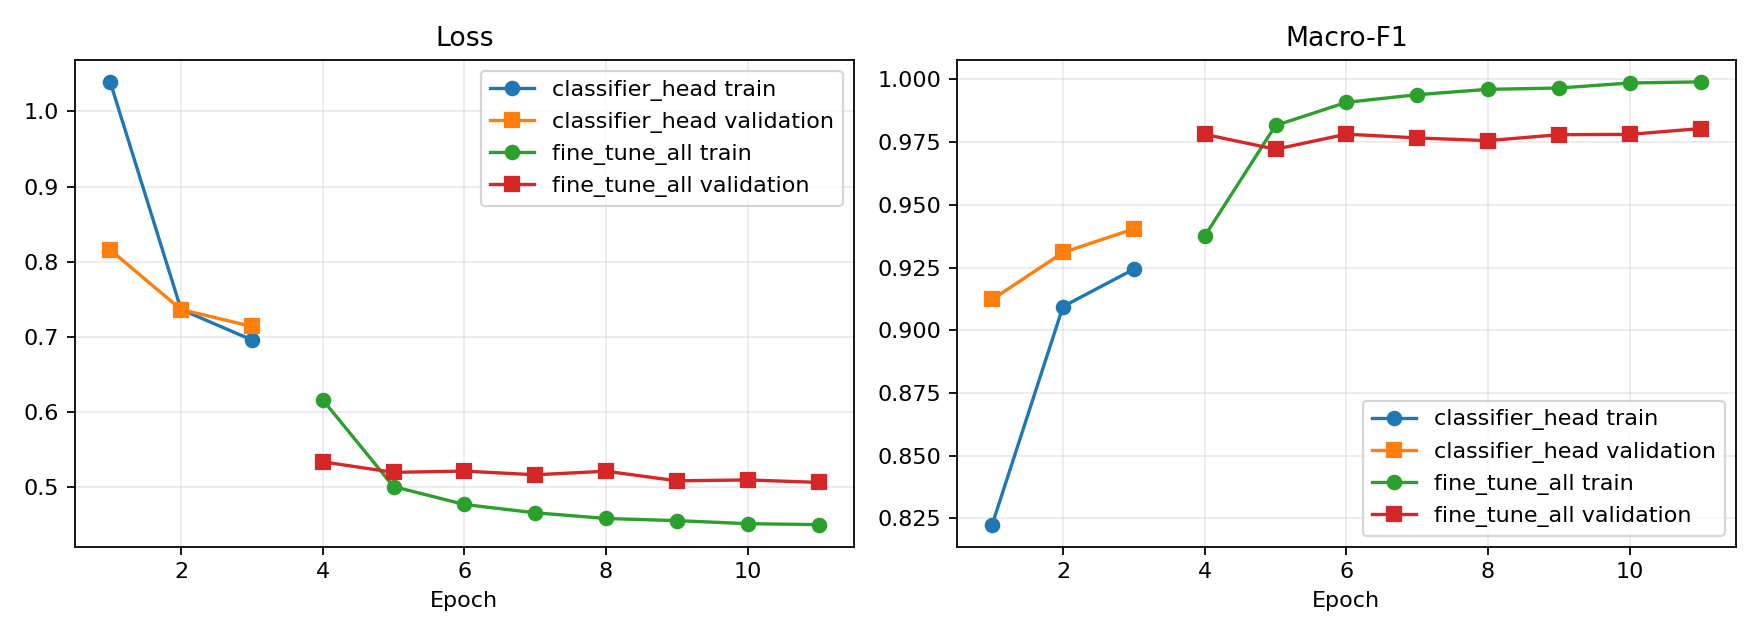

### EfficientNet-B0

Bobot ImageNet: `IMAGENET1K_V1`; checkpoint terbaik: `E:\OMING\Coding\Python\Deep-Learning-Cabai\data\processed\runs\efficientnet_b0_seed_42_20261115_104718_619397\best_checkpoint.pth`; durasi: 32.7 menit.

Jumlah parameter: 4,015,234.

Jumlah epoch: 11

| Epoch global | Tahap | Epoch tahap | Train loss | Train Macro-F1 | Validation loss | Validation Macro-F1 |
|---:|---|---:|---:|---:|---:|---:|
| 1 | classifier_head | 1 | 0.9125 | 0.8300 | 0.7201 | 0.9183 |
| 2 | classifier_head | 2 | 0.6786 | 0.9303 | 0.6694 | 0.9480 |
| 3 | classifier_head | 3 | 0.6493 | 0.9403 | 0.6522 | 0.9569 |
| 4 | fine_tune_all | 1 | 0.6817 | 0.9136 | 0.5716 | 0.9724 |
| 5 | fine_tune_all | 2 | 0.5488 | 0.9705 | 0.5426 | 0.9801 |
| 6 | fine_tune_all | 3 | 0.5256 | 0.9791 | 0.5531 | 0.9742 |
| 7 | fine_tune_all | 4 | 0.5084 | 0.9850 | 0.5425 | 0.9760 |
| 8 | fine_tune_all | 5 | 0.4981 | 0.9879 | 0.5330 | 0.9770 |
| 9 | fine_tune_all | 6 | 0.4915 | 0.9892 | 0.5324 | 0.9747 |
| 10 | fine_tune_all | 7 | 0.4897 | 0.9906 | 0.5350 | 0.9766 |
| 11 | fine_tune_all | 8 | 0.4865 | 0.9915 | 0.5293 | 0.9768 |

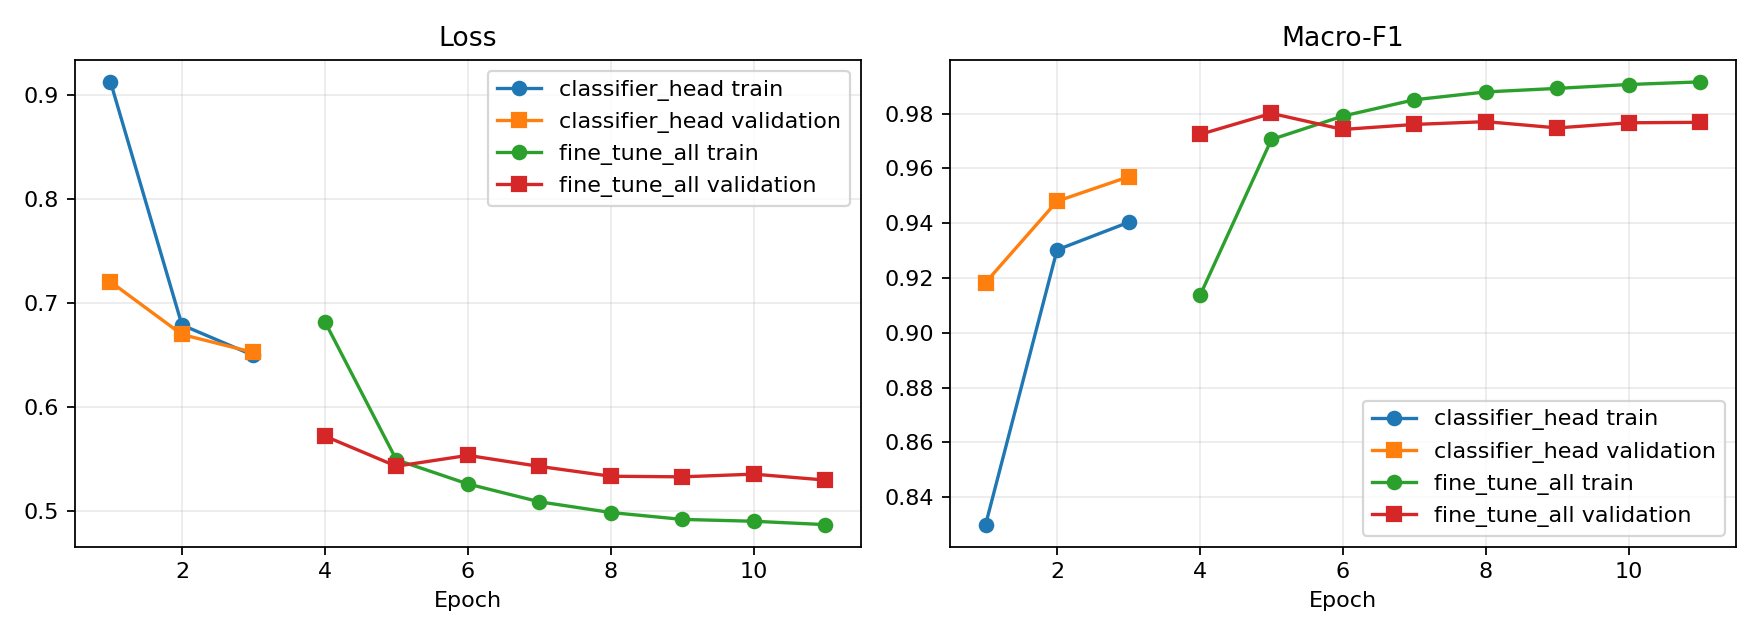

In [12]:
def latest_completed_run(model_slug):
    candidates = sorted(
        RUNS_DIR.glob(f"{model_slug}_seed_{PILOT_SEED}_*"),
        key=lambda path: path.name,
        reverse=True,
    )
    for run_dir in candidates:
        config_path = run_dir / "experiment_config.json"
        if config_path.is_file():
            with config_path.open(encoding="utf-8") as stream:
                config = json.load(stream)
            if config.get("status") == "completed":
                return run_dir
    raise FileNotFoundError(f"Hasil selesai belum tersedia untuk {model_slug}, seed {PILOT_SEED}")


experiment_dirs = {
    "MobileNetV3-Small": RUNS_DIR / f"mobilenet_v3_small_seed_{PILOT_SEED}",
    "ResNet-50": latest_completed_run(MODEL_SLUGS["ResNet-50"]),
    "EfficientNet-B0": latest_completed_run(MODEL_SLUGS["EfficientNet-B0"]),
}
comparison = []
experiment_results = {}
for architecture, run_dir in experiment_dirs.items():
    history_path = run_dir / "training_history.json"
    config_path = run_dir / "experiment_config.json"
    curves_path = run_dir / "training_curves.png"
    with history_path.open(encoding="utf-8") as stream:
        history = json.load(stream)
    with config_path.open(encoding="utf-8") as stream:
        config = json.load(stream)
    best_row = max(history, key=lambda row: row["validation_macro_f1"])
    checkpoint_path = run_dir / config["best_checkpoint"]
    if not checkpoint_path.is_file() or not curves_path.is_file():
        raise FileNotFoundError(f"Artefak checkpoint/grafik tidak lengkap: {run_dir}")
    if config["best_stage"] != best_row["stage"] or config["best_epoch"] != best_row["epoch"]:
        raise ValueError(f"Metadata checkpoint tidak cocok dengan history: {run_dir}")

    parameter_count = config.get("parameter_count")
    if parameter_count is None:
        model = build_model(architecture, pretrained=False, device=torch.device("cpu"))
        parameter_count = sum(parameter.numel() for parameter in model.parameters())
        del model
    result = {
        "architecture": architecture,
        "run_dir": run_dir,
        "history": history,
        "config": config,
        "best_row": best_row,
        "checkpoint_path": checkpoint_path,
        "curves_path": curves_path,
        "parameter_count": parameter_count,
    }
    experiment_results[architecture] = result
    comparison.append(result)

comparison_rows = [
    "| Model | Validation Macro-F1 terbaik | Validation loss pada checkpoint | Parameter | Durasi (menit) |",
    "|---|---:|---:|---:|---:|",
]
comparison_rows.extend(
    f"| {result['architecture']} | {result['best_row']['validation_macro_f1']:.4f} | "
    f"{result['best_row']['validation_loss']:.4f} | "
    f"{result['parameter_count']:,} | "
    f"{result['config']['training_duration_seconds'] / 60:.1f} |"
    for result in comparison
)
display(Markdown("## Perbandingan tiga model" + chr(10) * 2 + chr(10).join(comparison_rows)))

for result in comparison:
    architecture = result["architecture"]
    config = result["config"]
    history = result["history"]
    rows = [
        "| Epoch global | Tahap | Epoch tahap | Train loss | Train Macro-F1 | Validation loss | Validation Macro-F1 |",
        "|---:|---|---:|---:|---:|---:|---:|",
    ]
    rows.extend(
        f"| {row['global_epoch']} | {row['stage']} | {row['epoch']} | "
        f"{row['train_loss']:.4f} | {row['train_macro_f1']:.4f} | "
        f"{row['validation_loss']:.4f} | {row['validation_macro_f1']:.4f} |"
        for row in history
    )
    display(Markdown(
        f"### {architecture}\n\n"
        f"Bobot ImageNet: `{config['pretrained_weights']}`; "
        f"checkpoint terbaik: `{result['checkpoint_path']}`; "
        f"durasi: {config['training_duration_seconds'] / 60:.1f} menit.\n\n"
        f"Jumlah parameter: {result['parameter_count']:,}.\n\n"
        f"Jumlah epoch: {len(history)}\n\n" + chr(10).join(rows)
    ))
    display(NotebookImage(filename=str(result["curves_path"])))


### 14. Evaluasi checkpoint pada data validasi

Evaluasi menggunakan checkpoint terbaik seed 42 dan hanya membaca subset `validation`. Bagian ini menampilkan accuracy, Macro-Precision, Macro-Recall, Macro-F1, laporan per kelas, confusion matrix, ukuran checkpoint, jumlah parameter, waktu inferensi, dan contoh kesalahan.

Waktu inferensi memakai 5 batch warm-up, lalu median 3 pass atas tensor validasi yang sudah ditransformasi. Pengukuran mencakup transfer CPU ke GPU dan forward pass, tetapi tidak mencakup pembacaan file, transformasi citra, atau pemuatan checkpoint. Untuk CUDA dipakai CUDA Event dan sinkronisasi sesuai [dokumentasi timing PyTorch](https://docs.pytorch.org/docs/2.10/notes/cuda.html#asynchronous-execution). Evaluasi memakai [`torch.inference_mode`](https://docs.pytorch.org/docs/2.10/notes/autograd.html#inference-mode); tidak ada training atau evaluasi test set.


MobileNetV3-Small: Macro-F1 evaluasi 0.972502; history 0.972502; selisih 0.00e+00


ResNet-50: Macro-F1 evaluasi 0.980426; history 0.980426; selisih 0.00e+00


EfficientNet-B0: Macro-F1 evaluasi 0.980051; history 0.980051; selisih 0.00e+00


## Ringkasan evaluasi validasi

| Model | Accuracy | Macro-Precision | Macro-Recall | Macro-F1 | Parameter | Checkpoint (MiB) | Median inferensi (ms/citra) | Citra/detik |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| MobileNetV3-Small | 0.9706 | 0.9724 | 0.9738 | 0.9725 | 1,524,006 | 5.94 | 0.198 | 5059.10 |
| ResNet-50 | 0.9790 | 0.9800 | 0.9820 | 0.9804 | 23,520,326 | 90.02 | 1.919 | 521.08 |
| EfficientNet-B0 | 0.9790 | 0.9792 | 0.9814 | 0.9801 | 4,015,234 | 15.60 | 0.839 | 1191.64 |

### MobileNetV3-Small: metrik per kelas

| Kelas | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Bacterial Spot | 0.8957 | 0.9844 | 0.9380 | 192 |
| Cercospora Leaf Spot | 0.9920 | 0.9802 | 0.9861 | 253 |
| Curl Virus | 0.9727 | 0.9030 | 0.9365 | 237 |
| Healthy Leaf | 0.9867 | 1.0000 | 0.9933 | 222 |
| Nutrient Deficiency | 0.9873 | 0.9750 | 0.9811 | 160 |
| Powdery Mildew | 1.0000 | 1.0000 | 1.0000 | 127 |

### ResNet-50: metrik per kelas

| Kelas | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Bacterial Spot | 0.9227 | 0.9948 | 0.9574 | 192 |
| Cercospora Leaf Spot | 0.9921 | 0.9960 | 0.9941 | 253 |
| Curl Virus | 0.9908 | 0.9072 | 0.9471 | 237 |
| Healthy Leaf | 0.9867 | 1.0000 | 0.9933 | 222 |
| Nutrient Deficiency | 0.9876 | 0.9937 | 0.9907 | 160 |
| Powdery Mildew | 1.0000 | 1.0000 | 1.0000 | 127 |

### EfficientNet-B0: metrik per kelas

| Kelas | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Bacterial Spot | 0.9409 | 0.9948 | 0.9671 | 192 |
| Cercospora Leaf Spot | 0.9920 | 0.9842 | 0.9881 | 253 |
| Curl Virus | 0.9822 | 0.9325 | 0.9567 | 237 |
| Healthy Leaf | 0.9910 | 0.9955 | 0.9933 | 222 |
| Nutrient Deficiency | 0.9691 | 0.9812 | 0.9752 | 160 |
| Powdery Mildew | 1.0000 | 1.0000 | 1.0000 | 127 |

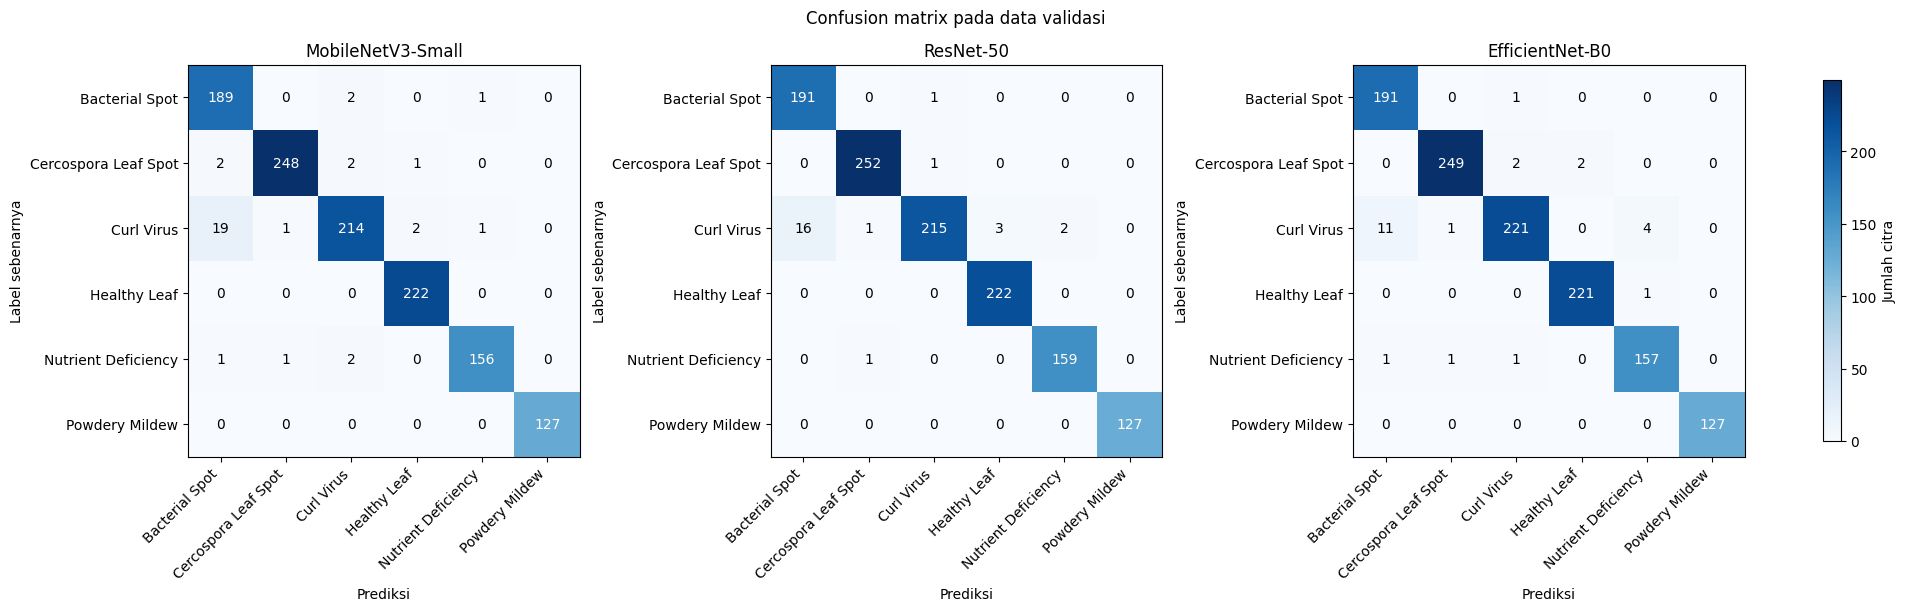

### Contoh salah klasifikasi: MobileNetV3-Small

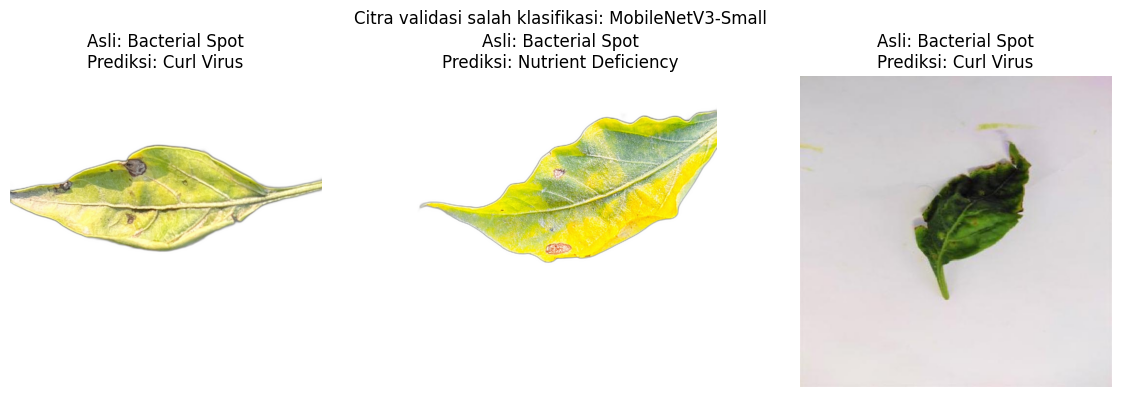

### Contoh salah klasifikasi: ResNet-50

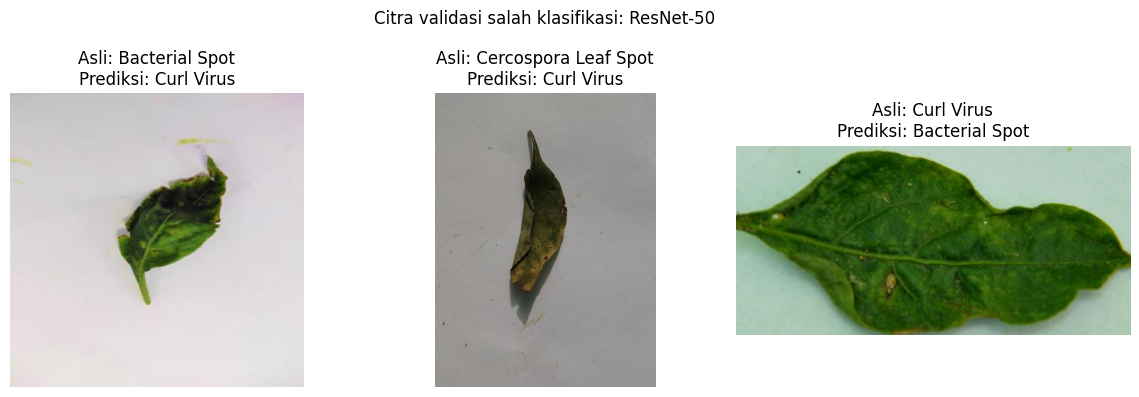

### Contoh salah klasifikasi: EfficientNet-B0

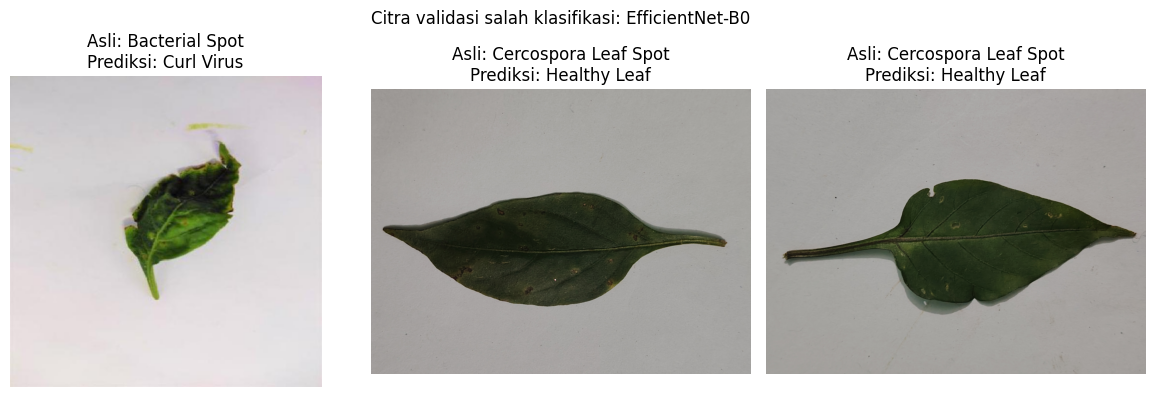

### Ringkasan perbandingan

- Macro-F1 validasi tertinggi: **ResNet-50** (0.9804); selisih dari posisi berikutnya 0.0004.
- Inferensi median tercepat pada perangkat ini: **MobileNetV3-Small** (0.198 ms/citra).
- Parameter paling sedikit: **MobileNetV3-Small** (1,524,006).
- Confusion matrix dan contoh kesalahan di atas hanya berasal dari subset validation. Test set tetap belum digunakan.

In [13]:
evaluation_order = ("MobileNetV3-Small", "ResNet-50", "EfficientNet-B0")
validation_batches = list(loaders["validation"])
validation_rows = loaders["validation"].dataset.rows
validation_targets = torch.cat([labels for _, labels in validation_batches])
assert len(validation_targets) == len(validation_rows)


def evaluate_checkpoint(architecture, result):
    checkpoint = torch.load(result["checkpoint_path"], map_location="cpu", weights_only=True)
    best_row = result["best_row"]
    if (
        checkpoint["architecture"] != architecture
        or checkpoint["seed"] != PILOT_SEED
        or checkpoint["stage"] != best_row["stage"]
        or checkpoint["epoch"] != best_row["epoch"]
    ):
        raise ValueError(f"Metadata checkpoint tidak cocok: {result['checkpoint_path']}")

    model = build_model(architecture, pretrained=False, device=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    del checkpoint
    model.eval()

    warmup_batches = validation_batches[:min(5, len(validation_batches))]
    predictions = None
    durations = []
    with torch.inference_mode():
        for _ in range(5):
            for images, _ in warmup_batches:
                model(images.to(DEVICE, non_blocking=(DEVICE.type == "cuda")))
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)

        for _ in range(3):
            outputs = []
            if DEVICE.type == "cuda":
                start_event = torch.cuda.Event(enable_timing=True)
                end_event = torch.cuda.Event(enable_timing=True)
                torch.cuda.synchronize(DEVICE)
                start_event.record()
            else:
                started_at = time.perf_counter()

            for images, _ in validation_batches:
                images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
                outputs.append(model(images).argmax(dim=1))

            if DEVICE.type == "cuda":
                end_event.record()
                torch.cuda.synchronize(DEVICE)
                durations.append(start_event.elapsed_time(end_event) / 1000)
            else:
                durations.append(time.perf_counter() - started_at)
            predictions = torch.cat(outputs).cpu()
            del outputs

    class_count = len(CLASS_LABELS)
    confusion = torch.bincount(
        validation_targets * class_count + predictions,
        minlength=class_count * class_count,
    ).reshape(class_count, class_count)
    true_positive = confusion.diag().float()
    false_positive = confusion.sum(dim=0).float() - true_positive
    false_negative = confusion.sum(dim=1).float() - true_positive
    support = confusion.sum(dim=1)
    precision = true_positive / (true_positive + false_positive).clamp(min=1)
    recall = true_positive / support.float().clamp(min=1)
    per_class_f1 = (
        2 * true_positive
        / (2 * true_positive + false_positive + false_negative).clamp(min=1)
    )
    metrics = {
        "accuracy": true_positive.sum().item() / confusion.sum().item(),
        "macro_precision": precision.mean().item(),
        "macro_recall": recall.mean().item(),
        "macro_f1": per_class_f1.mean().item(),
        "precision": precision,
        "recall": recall,
        "f1": per_class_f1,
        "support": support,
    }
    history_f1 = best_row["validation_macro_f1"]
    difference = abs(metrics["macro_f1"] - history_f1)
    if difference > 1e-6:
        raise ValueError(
            f"Macro-F1 hasil evaluasi berbeda dari history {architecture}: "
            f"{metrics['macro_f1']:.8f} vs {history_f1:.8f}"
        )

    result.update({
        "validation_metrics": metrics,
        "validation_confusion": confusion,
        "validation_predictions": predictions,
        "inference_seconds": float(np.median(durations)),
        "inference_repeats_seconds": durations,
        "checkpoint_size_mib": result["checkpoint_path"].stat().st_size / (1024 ** 2),
    })
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(
        f"{architecture}: Macro-F1 evaluasi {metrics['macro_f1']:.6f}; "
        f"history {history_f1:.6f}; selisih {difference:.2e}"
    )


for architecture in evaluation_order:
    evaluate_checkpoint(architecture, experiment_results[architecture])


evaluation_rows = [
    "| Model | Accuracy | Macro-Precision | Macro-Recall | Macro-F1 | Parameter | Checkpoint (MiB) | Median inferensi (ms/citra) | Citra/detik |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for architecture in evaluation_order:
    result = experiment_results[architecture]
    metrics = result["validation_metrics"]
    images_per_second = len(validation_rows) / result["inference_seconds"]
    milliseconds_per_image = result["inference_seconds"] * 1000 / len(validation_rows)
    evaluation_rows.append(
        f"| {architecture} | {metrics['accuracy']:.4f} | "
        f"{metrics['macro_precision']:.4f} | {metrics['macro_recall']:.4f} | "
        f"{metrics['macro_f1']:.4f} | {result['parameter_count']:,} | "
        f"{result['checkpoint_size_mib']:.2f} | {milliseconds_per_image:.3f} | "
        f"{images_per_second:.2f} |"
    )
display(Markdown("## Ringkasan evaluasi validasi" + chr(10) * 2 + chr(10).join(evaluation_rows)))

for architecture in evaluation_order:
    result = experiment_results[architecture]
    metrics = result["validation_metrics"]
    class_rows = [
        "| Kelas | Precision | Recall | F1-score | Support |",
        "|---|---:|---:|---:|---:|",
    ]
    for index, label in enumerate(CLASS_LABELS):
        class_rows.append(
            f"| {label} | {metrics['precision'][index].item():.4f} | "
            f"{metrics['recall'][index].item():.4f} | "
            f"{metrics['f1'][index].item():.4f} | "
            f"{int(metrics['support'][index])} |"
        )
    display(Markdown(f"### {architecture}: metrik per kelas\n\n" + chr(10).join(class_rows)))


figure, axes = plt.subplots(1, len(evaluation_order), figsize=(19, 6), constrained_layout=True)
for axis, architecture in zip(axes, evaluation_order):
    matrix = experiment_results[architecture]["validation_confusion"].numpy()
    image = axis.imshow(matrix, cmap="Blues")
    axis.set_title(architecture)
    axis.set_xlabel("Prediksi")
    axis.set_ylabel("Label sebenarnya")
    axis.set_xticks(range(len(CLASS_LABELS)), CLASS_LABELS, rotation=45, ha="right")
    axis.set_yticks(range(len(CLASS_LABELS)), CLASS_LABELS)
    threshold = matrix.max() / 2
    for row in range(len(CLASS_LABELS)):
        for column in range(len(CLASS_LABELS)):
            axis.text(
                column, row, str(matrix[row, column]),
                ha="center", va="center",
                color="white" if matrix[row, column] > threshold else "black",
            )
figure.colorbar(image, ax=axes, shrink=0.8, label="Jumlah citra")
figure.suptitle("Confusion matrix pada data validasi")
plt.show()


for architecture in evaluation_order:
    predictions = experiment_results[architecture]["validation_predictions"]
    incorrect_indices = torch.where(predictions != validation_targets)[0][:3].tolist()
    display(Markdown(f"### Contoh salah klasifikasi: {architecture}"))
    if not incorrect_indices:
        display(Markdown("Tidak ada citra validasi yang salah diklasifikasikan."))
        continue

    figure, axes = plt.subplots(1, len(incorrect_indices), figsize=(4 * len(incorrect_indices), 4))
    if len(incorrect_indices) == 1:
        axes = [axes]
    for axis, index in zip(axes, incorrect_indices):
        row = validation_rows[index]
        relative_path = PurePosixPath(row["relative_path"])
        path = IMAGE_DIR.joinpath(*relative_path.parts).resolve()
        if IMAGE_DIR not in path.parents:
            raise ValueError(f"Path manifest tidak aman: {relative_path}")
        with Image.open(path) as image:
            axis.imshow(image.convert("RGB"))
        predicted_label = CLASS_LABELS[int(predictions[index])]
        axis.set_title(f"Asli: {row['class_name']}\nPrediksi: {predicted_label}")
        axis.axis("off")
    figure.suptitle(f"Citra validasi salah klasifikasi: {architecture}")
    figure.tight_layout()
    plt.show()


ranked_macro_f1 = sorted(
    evaluation_order,
    key=lambda architecture: experiment_results[architecture]["validation_metrics"]["macro_f1"],
    reverse=True,
)
fastest_model = min(evaluation_order, key=lambda architecture: experiment_results[architecture]["inference_seconds"])
smallest_model = min(evaluation_order, key=lambda architecture: experiment_results[architecture]["parameter_count"])
top_gap = (
    experiment_results[ranked_macro_f1[0]]["validation_metrics"]["macro_f1"]
    - experiment_results[ranked_macro_f1[1]]["validation_metrics"]["macro_f1"]
)
display(Markdown(
    "### Ringkasan perbandingan\n\n"
    f"- Macro-F1 validasi tertinggi: **{ranked_macro_f1[0]}** "
    f"({experiment_results[ranked_macro_f1[0]]['validation_metrics']['macro_f1']:.4f}); "
    f"selisih dari posisi berikutnya {top_gap:.4f}.\n"
    f"- Inferensi median tercepat pada perangkat ini: **{fastest_model}** "
    f"({experiment_results[fastest_model]['inference_seconds'] * 1000 / len(validation_rows):.3f} ms/citra).\n"
    f"- Parameter paling sedikit: **{smallest_model}** "
    f"({experiment_results[smallest_model]['parameter_count']:,}).\n"
    "- Confusion matrix dan contoh kesalahan di atas hanya berasal dari subset validation. "
    "Test set tetap belum digunakan."
))